In [1]:
from search_utils.utils import define_env
from search_utils.SearchAlgorithms import BFS, DFS, DFS_poda, BFS_poda, LowestSearch_Poda
from queue import PriorityQueue
from adabyron_environment.AdaByronDEMO_v2 import AdaByronDEMO
from adabyron_environment.agents.airConditioning_v2 import Airconditioning
from adabyron_environment.agents.storageBattery_v2 import StorageBattery
import itertools
from itertools import permutations
from datetime import date
import matplotlib.pyplot as plt
import random
import numpy as np
# import copy

In [2]:
generated = [random.random() for i in range(0, 96)]

consump = [i+30 for i in generated]

print(np.dot(consump, generated))
env = AdaByronDEMO(agents = [Airconditioning("aire1"), StorageBattery("bateria1", capacity = 80)], 
                 consumption_curve = consump, 
                 generated_energy = generated, 
                 energy_price = generated, 
                 season = 0, 
                 temp_range = [21, 25], 
                 summer_temp = 30, 
                 winter_temp = 15,
                 expected_saving_percentage = 5)
action_space = env.action_space
initial = env.reset()

1634.2059027487498
0.95
1


In [3]:
#resultado = BFS(initial, env)
resultado = LowestSearch_Poda(initial, env, 10)

Achieved saving of 5%
Found new best solution with price 242.36359753727172
Achieved saving of 5%
Achieved saving of 5%
Achieved saving of 5%
Found new best solution with price 239.27191218621098
Achieved saving of 5%
Found new best solution with price 237.62600027896198
Achieved saving of 5%
Found new best solution with price 234.53431492790125
Achieved saving of 5%
Found new best solution with price 234.39686800595436
Achieved saving of 5%
Found new best solution with price 232.75095609870536
Achieved saving of 5%
Found new best solution with price 229.65927074764463
Achieved saving of 5%
Found new best solution with price 228.40011401013416
Achieved saving of 5%
Found new best solution with price 225.30842865907343
Achieved saving of 5%
Found new best solution with price 225.17098173712654


In [3]:
arrayGrande = []
arrayGrande_Temp = []
precios = []
for r in resultado:
    res = []
    temp = []
    actual = r
    precios.append(actual.cumulative_price)
    while(True):
        temp.append(actual.specific["actual_temp"])
        res.append(actual.consumption)
        if actual.day_step == 0:
            break
        actual = actual.father
    arrayGrande.append(res)
    arrayGrande_Temp.append(temp)

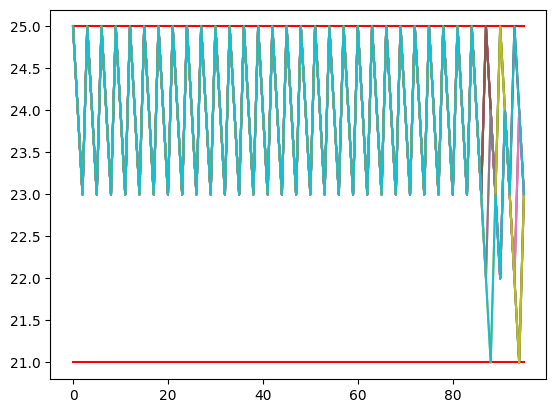

In [4]:
for r in arrayGrande_Temp:
    r.reverse()

tempH = [25 for i in range(0, 96)]
tempL = [21 for i in range(0, 96)]

plt.plot(tempH, color='red')
plt.plot(tempL, color = 'red')

for a in arrayGrande_Temp:
    plt.plot(a)

plt.savefig("images/Search/LS_Poda/Temp_{}.png".format(date.today()))

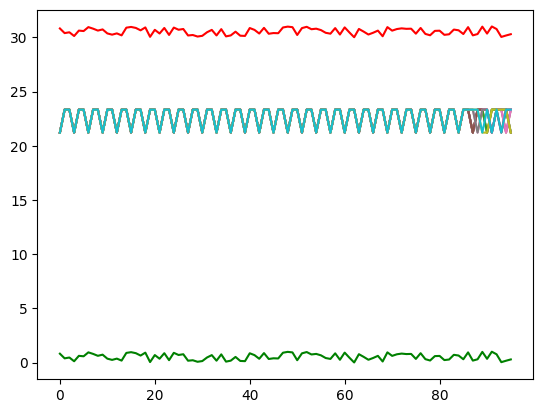

In [5]:
for r in arrayGrande:
    r.reverse()


plt.plot(generated, color='green')
plt.plot(consump, color = 'red')

for a in arrayGrande:
    plt.plot(a)

plt.savefig("images/Search/LS_Poda/Consumo_{}.png".format(date.today()))

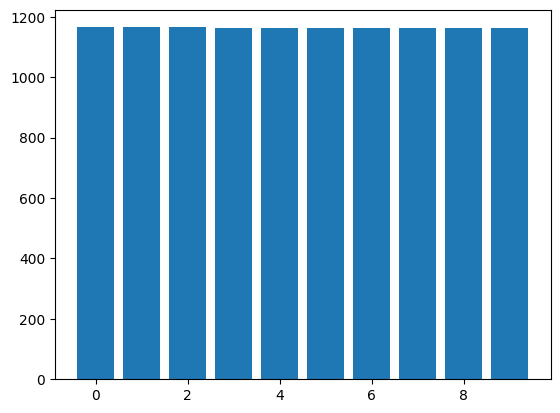

In [6]:
plt.bar(range(0, len(precios)), precios)
plt.savefig("images/Search/LS_Poda/Precios_{}.png".format(date.today()))

In [7]:
for i in range(0,5):
    if i == 3:
        continue
    else:
        print(i)

0
1
2
4
